In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv('/kaggle/input/datasets/mohansacharya/graduate-admissions/Admission_Predict_Ver1.1.csv')

In [4]:
data.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [5]:
data.shape

(500, 9)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB


In [7]:
data.isna().sum()

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(0)

In [9]:
df = data.drop(columns = ['Serial No.'])

In [10]:
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


In [11]:
X = df.iloc[:,0:-1]
y = df.iloc[:,-1]

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=5)

In [13]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(400, 7) (400,)
(100, 7) (100,)


In [14]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [16]:
model = Sequential([
    Dense(units=7, activation='relu', input_dim=7),
    Dense(units=7, activation='relu'),
    Dense(units=1, activation='linear')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1792836136.343969     208 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792836136.346130     208 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120 (480.00 B)

 Trainable params: 120 (480.00 B)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['r2_score'])

In [19]:
history = model.fit(X_train_scaled, y_train, epochs=25, validation_split=0.2)

Epoch 1/25
 1/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - loss: 0.2592 - r2_score: -7.7871

I0000 00:00:1792836152.314679     268 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 162ms/step - loss: 0.2378 - r2_score: -10.2769 - val_loss: 0.1887 - val_r2_score: -8.8419
Epoch 2/25
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1608 - r2_score: -6.6232 - val_loss: 0.1207 - val_r2_score: -5.2963
Epoch 3/25
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0954 - r2_score: -3.5260 - val_loss: 0.0687 - val_r2_score: -2.5851
Epoch 4/25
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0519 - r2_score: -1.4631 - val_loss: 0.0392 - val_r2_score: -1.0434
Epoch 5/25
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0323 - r2_score: -0.5338 - val_loss: 0.0300 - val_r2_score: -0.5665
Epoch 6/25
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0285 - r2_score: -0.3497 - val_loss: 0.0290 - val_r2_score: -0.5144
Epoch 7/25
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0280 - r2_score: -0.3263 - val_loss: 0.0280 - val_r2_score: -0.4609
Epoch 8/25
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0268 - r2_score: -0.2731 - val_loss: 0.0270 -

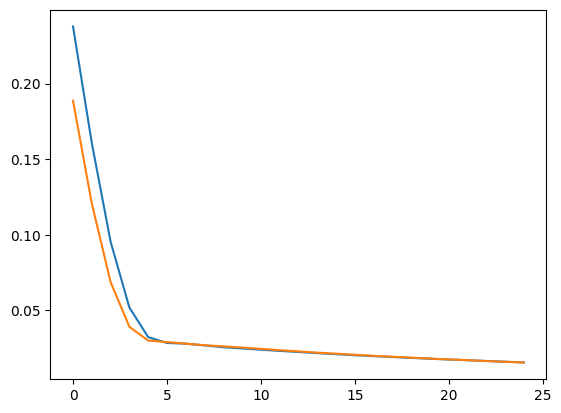

In [20]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])